In [45]:
from keras.models import Sequential
from keras.layers import SimpleRNN

model = Sequential()
model.add(SimpleRNN(3, input_shape=(2, 10)))
#(2,10) 2는 타이밍 10은 입력할 백터사이즈 3은 은닉층
#model = Sequential()

#units × (features + units + 1)
# = 3 × (10 + 3 + 1)
# = 3 × 14
# = 42

In [46]:
model.summary()


Model: "sequential_18"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_14 (SimpleRNN)   (None, 3)                 42        
                                                                 
Total params: 42 (168.00 Byte)
Trainable params: 42 (168.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [47]:
# 이전꺼
from keras.models import Sequential
from keras.layers import SimpleRNN

model = Sequential()
model.add(SimpleRNN(3, batch_input_shape=(8, 2, 10)))
model.summary()

Model: "sequential_19"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_15 (SimpleRNN)   (8, 3)                    42        
                                                                 
Total params: 42 (168.00 Byte)
Trainable params: 42 (168.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [48]:
# 신버전
from keras.models import Sequential
from keras.layers import SimpleRNN
import numpy as np

inputs = np.random.random((8, 2, 10))   # (샘플 8개, 타임스텝 2, 특성 10)

# 입력 구조 설계
model = Sequential()
model.add(SimpleRNN(3))
model(inputs)        # 실제 데이터를 한 번 넣어서 모델을 빌드
model.summary()

Model: "sequential_20"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_16 (SimpleRNN)   (8, 3)                    42        
                                                                 
Total params: 42 (168.00 Byte)
Trainable params: 42 (168.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [49]:
# 이전꺼
from keras.models import Sequential
from keras.layers import SimpleRNN

model = Sequential()
model.add(SimpleRNN(3, batch_input_shape=(8, 2, 10),return_sequences=True))
model.summary()

Model: "sequential_21"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_17 (SimpleRNN)   (8, 2, 3)                 42        
                                                                 
Total params: 42 (168.00 Byte)
Trainable params: 42 (168.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [50]:
# 신버전
from keras.models import Sequential
from keras.layers import SimpleRNN
import numpy as np

inputs = np.random.random((8, 2, 10))   # (샘플 8개, 타임스텝 2, 특성 10)

# 입력 구조 설계
model = Sequential()
model.add(SimpleRNN(3, return_sequences=True))
#은닉층추가하고싶으면 이걸 추가해주면 됨 
model(inputs)        # 실제 데이터를 한 번 넣어서 모델을 빌드
model.summary()



Model: "sequential_22"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_18 (SimpleRNN)   (8, 2, 3)                 42        
                                                                 
Total params: 42 (168.00 Byte)
Trainable params: 42 (168.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [51]:
### RNN을 이용하여 텍스트 생성하기
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
from tensorflow.keras.utils import to_categorical

In [52]:
text="""경마장에 있는 말이 뛰고 있다 \n 그의 말이 법이다 \n 가는 말이 고와야 오는 말이 곱다"""

In [53]:
t = Tokenizer()
t.fit_on_texts([text])
#토큰들을 생성하여 단와야 인덱스를 생성한다.
vocab_size = len(t.word_index) + 1
print("단어 집합의 크기 : %d" % vocab_size)

단어 집합의 크기 : 12


In [54]:
t.word_index
#원핫인코딩해서 메칭시켜주기쉽게하기위해 단어길이 +1해줌 

{'말이': 1,
 '경마장에': 2,
 '있는': 3,
 '뛰고': 4,
 '있다': 5,
 '그의': 6,
 '법이다': 7,
 '가는': 8,
 '고와야': 9,
 '오는': 10,
 '곱다': 11}

In [55]:
sequences = list()
for line in text.split("\n"):
    #t.text_to_sequences():문장에 있는 각 단어 인덱스를 사용하여  점수로 변환하는 함수
    encoded = t.texts_to_sequences([line])[0]
    for i in range(1, len(encoded)):
        sequence = encoded[:i+1]
        sequences.append(sequence)

print("학습에 사용할 샘플의 개수: %d" % len(sequences))


학습에 사용할 샘플의 개수: 11


In [56]:
sequences = list()
for line in text.split("\n"):
    #t.text_to_sequences():문장에 있는 각 단어 인덱스를 사용하여  점수로 변환하는 함수
    print(t.texts_to_sequences([line]))
    encoded = t.texts_to_sequences([line])[0]
    for i in range(1, len(encoded)):
        sequence = encoded[:i+1]
        sequences.append(sequence)

print("학습에 사용할 샘플의 개수: %d" % len(sequences))


[[2, 3, 1, 4, 5]]
[[6, 1, 7]]
[[8, 1, 9, 10, 1, 11]]
학습에 사용할 샘플의 개수: 11


In [57]:
sequences

[[2, 3],
 [2, 3, 1],
 [2, 3, 1, 4],
 [2, 3, 1, 4, 5],
 [6, 1],
 [6, 1, 7],
 [8, 1],
 [8, 1, 9],
 [8, 1, 9, 10],
 [8, 1, 9, 10, 1],
 [8, 1, 9, 10, 1, 11]]

In [58]:
# 학습할 데이터의 길이를 동일하게 맞춰줌
max_len = max(len(i) for i in sequences)
print("샘플의 최대 길이: {}".format(max_len))

샘플의 최대 길이: 6


- pad_sequences(sequences, maxlen=None, dtype='int32', padding='pre', truncating='pre', value=0.0)
    - 문장의 길이를 maxlen 인자로 맞추어 준다. 120으로 지정했다면 120보다 짧은 문장은 0으로 채워서 120단어로 맞춰주고 120보다 긴 문장은 120단어까지만 잘라낸다.
    - (num_samples, num_timesteps)으로 2차원의 numpy 배열로 만들어준다. maxlen을 120으로 지정하였다면, num_timesteps도 120이 된다.
    - 인수
        - padding : 'pre' or 'post'
        - truncating : 'pre' or 'post'
        - value : 채워질 값. default는 0

In [59]:
sequences = pad_sequences(sequences, maxlen=max_len, padding="pre")
print(sequences)

[[ 0  0  0  0  2  3]
 [ 0  0  0  2  3  1]
 [ 0  0  2  3  1  4]
 [ 0  2  3  1  4  5]
 [ 0  0  0  0  6  1]
 [ 0  0  0  6  1  7]
 [ 0  0  0  0  8  1]
 [ 0  0  0  8  1  9]
 [ 0  0  8  1  9 10]
 [ 0  8  1  9 10  1]
 [ 8  1  9 10  1 11]]


In [60]:
#앞에가 학습할데이터 뒤에가 예측할데이터

In [61]:
sequences=np.array(sequences)
x=sequences[:,:-1]
y=sequences[:,-1]

In [62]:
print(y)

[ 3  1  4  5  1  7  1  9 10  1 11]


In [63]:
y = to_categorical(y, num_classes=vocab_size)
print(y.shape)  # (11, 12)


(11, 12)


- tf.keras.layers.Embedding(
    input_dim, output_dim, embeddings_initializer='uniform',
    embeddings_regularizer=None, activity_regularizer=None,
    embeddings_constraint=None, mask_zero=False, input_length=None, **kwargs)
    - 인수
        - input_dim : 입력 크기
        - output_dim : 출력 크기
        - input_length : 입력 데이터의 길이

In [ ]:
#이전모델
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

model = Sequential()
model.add(Embedding(vocab_size, 6, input_length=max_len-1))
model.add(SimpleRNN(32))
model.add(Dense(vocab_size, activation="softmax"))
model.summary()


Model: "sequential_25"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_5 (Embedding)     (None, 5, 6)              72        
                                                                 
 simple_rnn_21 (SimpleRNN)   (None, 32)                1248      
                                                                 
 dense_5 (Dense)             (None, 12)                396       
                                                                 
Total params: 1716 (6.70 KB)
Trainable params: 1716 (6.70 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
#이후모델
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

model = Sequential()
model.add(Embedding(vocab_size, 6))
model.add(SimpleRNN(32))
model.add(Dense(vocab_size, activation='softmax'))
model.build(input_shape=(None, max_len-1))
model.summary()


Model: "sequential_24"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_4 (Embedding)     (None, None, 6)           72        
                                                                 
 simple_rnn_20 (SimpleRNN)   (None, 32)                1248      
                                                                 
 dense_4 (Dense)             (None, 12)                396       
                                                                 
Total params: 1716 (6.70 KB)
Trainable params: 1716 (6.70 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [67]:
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.fit(x, y, epochs=200, verbose=2)



Epoch 1/200


1/1 - 1s - loss: 2.5101 - accuracy: 0.0000e+00 - 1s/epoch - 1s/step
Epoch 2/200
1/1 - 0s - loss: 2.5001 - accuracy: 0.0000e+00 - 11ms/epoch - 11ms/step
Epoch 3/200
1/1 - 0s - loss: 2.4904 - accuracy: 0.0909 - 5ms/epoch - 5ms/step
Epoch 4/200
1/1 - 0s - loss: 2.4809 - accuracy: 0.1818 - 6ms/epoch - 6ms/step
Epoch 5/200
1/1 - 0s - loss: 2.4716 - accuracy: 0.3636 - 5ms/epoch - 5ms/step
Epoch 6/200
1/1 - 0s - loss: 2.4622 - accuracy: 0.3636 - 5ms/epoch - 5ms/step
Epoch 7/200
1/1 - 0s - loss: 2.4528 - accuracy: 0.3636 - 6ms/epoch - 6ms/step
Epoch 8/200
1/1 - 0s - loss: 2.4433 - accuracy: 0.3636 - 4ms/epoch - 4ms/step
Epoch 9/200
1/1 - 0s - loss: 2.4336 - accuracy: 0.4545 - 4ms/epoch - 4ms/step
Epoch 10/200
1/1 - 0s - loss: 2.4237 - accuracy: 0.3636 - 4ms/epoch - 4ms/step
Epoch 11/200
1/1 - 0s - loss: 2.4133 - accuracy: 0.3636 - 6ms/epoch - 6ms/step
Epoch 12/200
1/1 - 0s - loss: 2.4025 - accuracy: 0.3636 - 4ms/epoch - 4ms/step
Epoch 13/200
1/1 - 0s - loss: 2.3912 - accuracy: 0

In [68]:
def sentence_generation(model, t, current_word, n):
    init_word = current_word
    sentence = ""
    for _ in range(n):
        encoded = t.texts_to_sequences([current_word])[0]
        encoded = pad_sequences([encoded], maxlen=max_len-1, padding="pre")
        temp = model.predict(encoded, verbose=0)
        result = np.argmax(temp, axis=1)[0]
        for word, index in t.word_index.items():
            if index == result:
                break

        current_word = current_word + " " + word
        sentence = sentence + " " + word

    sentence = init_word + sentence
    return sentence

In [69]:
print(sentence_generation(model, t, "경마장에", 4))
# 경마장에 있는 말이 뛰고 있다

경마장에 있는 말이 뛰고 있다


In [70]:
print(sentence_generation(model, t, "체포하겠어", 4))


체포하겠어 있는 말이 법이다 오는


In [ ]:
#LSTM을 이용하여 텍스트 생성하기

In [1]:
import pandas as pd
from string import punctuation
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
from tensorflow.keras.utils import to_categorical

In [2]:
df = pd.read_csv("ArticlesApril2018.csv")
df.head()

,articleID,articleWordCount,byline,documentType,headline,keywords,multimedia,newDesk,printPage,pubDate,sectionName,snippet,source,typeOfMaterial,webURL
0,5adf6684068401528a2aa69b,781,By JOHN BRANCH,article,Former N.F.L. Cheerleaders’ Settlement Offer: ...,"['Workplace Hazards and Violations', 'Football...",68,Sports,0,2018-04-24 17:16:49,Pro Football,"“I understand that they could meet with us, pa...",The New York Times,News,https://www.nytimes.com/2018/04/24/sports/foot...
1,5adf653f068401528a2aa697,656,By LISA FRIEDMAN,article,E.P.A. to Unveil a New Rule. Its Effect: Less ...,"['Environmental Protection Agency', 'Pruitt, S...",68,Climate,0,2018-04-24 17:11:21,Unknown,The agency plans to publish a new regulation T...,The New York Times,News,https://www.nytimes.com/2018/04/24/climate/epa...
2,5adf4626068401528a2aa628,2427,By PETE WELLS,article,"The New Noma, Explained","['Restaurants', 'Noma (Copenhagen, Restaurant)...",66,Dining,0,2018-04-24 14:58:44,Unknown,What’s it like to eat at the second incarnatio...,The New York Times,News,https://www.nytimes.com/2018/04/24/dining/noma...
3,5adf40d2068401528a2aa619,626,By JULIE HIRSCHFELD DAVIS and PETER BAKER,article,Unknown,"['Macron, Emmanuel (1977- )', 'Trump, Donald J...",68,Washington,0,2018-04-24 14:35:57,Europe,President Trump welcomed President Emmanuel Ma...,The New York Times,News,https://www.nytimes.com/2018/04/24/world/europ...
4,5adf3d64068401528a2aa60f,815,By IAN AUSTEN and DAN BILEFSKY,article,Unknown,"['Toronto, Ontario, Attack (April, 2018)', 'Mu...",68,Foreign,0,2018-04-24 14:21:21,Canada,"Alek Minassian, 25, a resident of Toronto’s Ri...",The New York Times,News,https://www.nytimes.com/2018/04/24/world/canad...


In [3]:
print("열의 개수:", len(df.columns))
print(df.columns)

열의 개수: 15
Index(['articleID', 'articleWordCount', 'byline', 'documentType', 'headline',
       'keywords', 'multimedia', 'newDesk', 'printPage', 'pubDate',
       'sectionName', 'snippet', 'source', 'typeOfMaterial', 'webURL'],
      dtype='object')


In [6]:
df["headline"].isnull().values.any()

False

In [5]:
headline = []
headline.extend(list(df.headline.values))
headline[:5]

['Former N.F.L. Cheerleaders’ Settlement Offer: $1 and a Meeting With Goodell',
 'E.P.A. to Unveil a New Rule. Its Effect: Less Science in Policymaking.',
 'The New Noma, Explained',
 'Unknown',
 'Unknown']

In [7]:
print("총 샘플의 개수:{}".format(len(headline)))


총 샘플의 개수:1324


In [10]:
headline = [n for n in headline if n != "Unknown"]
print("노이즈값 제거 후 샘플의 개수: {}".format(len(headline)))

노이즈값 제거 후 샘플의 개수: 1214


In [11]:
headline[:5]

['Former N.F.L. Cheerleaders’ Settlement Offer: $1 and a Meeting With Goodell',
 'E.P.A. to Unveil a New Rule. Its Effect: Less Science in Policymaking.',
 'The New Noma, Explained',
 'How a Bag of Texas Dirt  Became a Times Tradition',
 'Is School a Place for Self-Expression?']

In [12]:
def repreprocessing(s):
    s=s.encode("utf8").decode("ascil","ignore")
    return"".join(c for c in s if c not in punctuation).lower()

In [14]:
import codecs
codecs.register(lambda name: codecs.lookup("ascii") if name == "ascil" else None)

In [ ]:
text=[repreprocessing(x) for x in headline]
text[:5]
#구두점 제거 

['former nfl cheerleaders settlement offer 1 and a meeting with goodell',
 'epa to unveil a new rule its effect less science in policymaking',
 'the new noma explained',
 'how a bag of texas dirt  became a times tradition',
 'is school a place for selfexpression']

In [17]:
t = Tokenizer()
t.fit_on_texts(text)
# 토큰들을 생성하여 단어와 인덱스를 생성한다.
vocab_size = len(t.word_index) + 1
print("단어 집합의 크기 : %d" % vocab_size)

단어 집합의 크기 : 3494


In [18]:
sequences = list()
for line in text:
    encoded = t.texts_to_sequences([line])[0]
    for i in range(1, len(encoded)):
        sequence = encoded[:i+1]
        sequences.append(sequence)

print("학습에 사용할 샘플의 개수: %d" % len(sequences))

학습에 사용할 샘플의 개수: 7803


In [20]:
max_len = max(len(s) for s in sequences)
print("샘플의 최대 길이: {}".format(max_len))

샘플의 최대 길이: 24


In [21]:
sequences = pad_sequences(sequences, maxlen=max_len, padding="pre")
print(sequences[:3])

[[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0   99  269]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0   99  269  371]
 [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0   99  269  371 1115]]


In [22]:
sequences = np.array(sequences)
x=sequences[:,:-1]
y=sequences[:,-1]

In [23]:
y=to_categorical(y,num_classes=vocab_size)

In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, LSTM

In [27]:
model = Sequential()
model.add(Embedding(vocab_size, 10))
model.add(LSTM(128))
model.add(Dense(vocab_size, activation="softmax"))
model.build(input_shape=(None, max_len-1))
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_1 (Embedding)     (None, None, 10)          34940     
                                                                 
 lstm_1 (LSTM)               (None, 128)               71168     
                                                                 
 dense_1 (Dense)             (None, 3494)              450726    
                                                                 
Total params: 556834 (2.12 MB)
Trainable params: 556834 (2.12 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [29]:
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.fit(x, y, epochs=200, verbose=2)


Epoch 1/200


244/244 - 4s - loss: 7.6365 - accuracy: 0.0302 - 4s/epoch - 16ms/step
Epoch 2/200
244/244 - 3s - loss: 7.1111 - accuracy: 0.0317 - 3s/epoch - 11ms/step
Epoch 3/200
244/244 - 3s - loss: 6.9766 - accuracy: 0.0322 - 3s/epoch - 11ms/step
Epoch 4/200
244/244 - 3s - loss: 6.8566 - accuracy: 0.0413 - 3s/epoch - 11ms/step
Epoch 5/200
244/244 - 3s - loss: 6.7049 - accuracy: 0.0445 - 3s/epoch - 11ms/step
Epoch 6/200
244/244 - 3s - loss: 6.5313 - accuracy: 0.0447 - 3s/epoch - 11ms/step
Epoch 7/200
244/244 - 3s - loss: 6.3394 - accuracy: 0.0552 - 3s/epoch - 12ms/step
Epoch 8/200
244/244 - 3s - loss: 6.1289 - accuracy: 0.0579 - 3s/epoch - 11ms/step
Epoch 9/200
244/244 - 3s - loss: 5.9178 - accuracy: 0.0632 - 3s/epoch - 12ms/step
Epoch 10/200
244/244 - 3s - loss: 5.7155 - accuracy: 0.0692 - 3s/epoch - 11ms/step
Epoch 11/200
244/244 - 3s - loss: 5.5306 - accuracy: 0.0743 - 3s/epoch - 10ms/step
Epoch 12/200
244/244 - 3s - loss: 5.3568 - accuracy: 0.0801 - 3s/epoch - 11ms/step
Epoch 13/2

In [30]:
def sentence_generation(model, t, current_word, n):
    init_word = current_word
    sentence = ""
    for _ in range(n):
        encoded = t.texts_to_sequences([current_word])[0]
        encoded = pad_sequences([encoded], maxlen=max_len-1, padding="pre")
        temp = model.predict(encoded, verbose=0)
        result = np.argmax(temp, axis=1)[0]
        for word, index in t.word_index.items():
            if index == result:
                break

        current_word = current_word + " " + word
        sentence = sentence + " " + word

    sentence = init_word + sentence
    return sentence

In [31]:
print(sentence_generation(model, t, "i", 10))

i want to be rich and im not sorry president fuels


In [33]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Bidirectional

hidden_units = 3
timesteps = 10
input_dim = 5

model = Sequential()
model.add(Bidirectional(SimpleRNN(hidden_units, return_sequences=True), input_shape=(timesteps, input_dim)))
#model.summary()

In [34]:
model = Sequential()
model.add(Bidirectional(SimpleRNN(hidden_units, return_sequences=True), input_shape=(timesteps, input_dim)))
model.add(Bidirectional(SimpleRNN(hidden_units, return_sequences=True)))
model.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 bidirectional_2 (Bidirecti  (None, 10, 6)             54        
 onal)                                                           
                                                                 
 bidirectional_3 (Bidirecti  (None, 10, 6)             60        
 onal)                                                           
                                                                 
Total params: 114 (456.00 Byte)
Trainable params: 114 (456.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [35]:
model = Sequential()
model.add(Embedding(vocab_size, 10, input_length=max_len-1))
model.add(Bidirectional(LSTM(128)))  # 양방향 LSTM 사용
model.add(Dense(vocab_size, activation="softmax"))
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.fit(x, y, epochs=200, verbose=2)

Epoch 1/200
244/244 - 5s - loss: 7.6798 - accuracy: 0.0287 - 5s/epoch - 21ms/step
Epoch 2/200
244/244 - 3s - loss: 7.1532 - accuracy: 0.0296 - 3s/epoch - 13ms/step
Epoch 3/200
244/244 - 3s - loss: 7.0258 - accuracy: 0.0306 - 3s/epoch - 13ms/step
Epoch 4/200
244/244 - 3s - loss: 6.8696 - accuracy: 0.0413 - 3s/epoch - 12ms/step
Epoch 5/200
244/244 - 3s - loss: 6.6478 - accuracy: 0.0482 - 3s/epoch - 12ms/step
Epoch 6/200
244/244 - 3s - loss: 6.3745 - accuracy: 0.0552 - 3s/epoch - 13ms/step
Epoch 7/200
244/244 - 3s - loss: 6.0863 - accuracy: 0.0597 - 3s/epoch - 13ms/step
Epoch 8/200
244/244 - 3s - loss: 5.7879 - accuracy: 0.0663 - 3s/epoch - 12ms/step
Epoch 9/200
244/244 - 3s - loss: 5.4931 - accuracy: 0.0695 - 3s/epoch - 13ms/step
Epoch 10/200
244/244 - 3s - loss: 5.1963 - accuracy: 0.0797 - 3s/epoch - 12ms/step
Epoch 11/200
244/244 - 3s - loss: 4.9244 - accuracy: 0.0969 - 3s/epoch - 13ms/step
Epoch 12/200
244/244 - 3s - loss: 4.6637 - accuracy: 0.1194 - 3s/epoch - 13ms/step
Epoch 13/200


In [36]:
import numpy as np
list_a=[1,2,3,4,5]
print(list_a)
print(np.diff(list_a))


[1, 2, 3, 4, 5]
[1 1 1 1]


In [ ]:
#로그변환

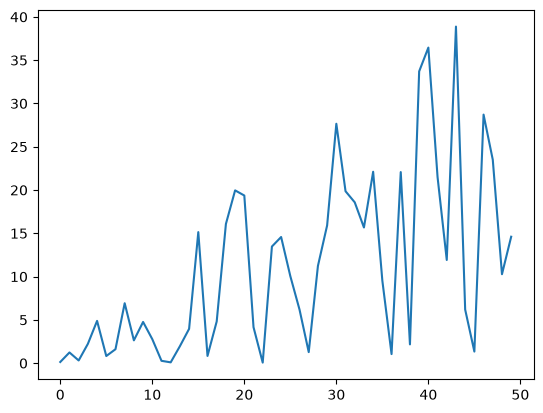

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt

#50개의 랜덤 시계열 생성
list_a=np.random.rand(50)

#idx만큼 증가하는 추세를 추가
list_a=[(idx+1)*val for idx,val in enumerate(list_a)]
plt.plot(list_a)
plt.show()

C:\Users\Win11Pro\AppData\Local\Temp\ipykernel_22656\2201908033.py:6: RuntimeWarning: invalid value encountered in log
  litst = np.log(list_a)


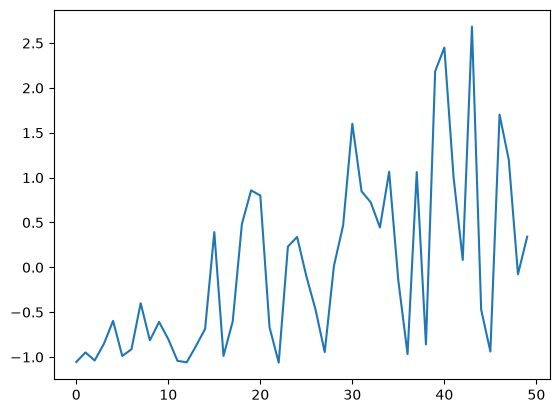

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt

#50개의 랜덤 시계열 생성
litst = np.log(list_a)
plt.plot(list_a)
plt.show()

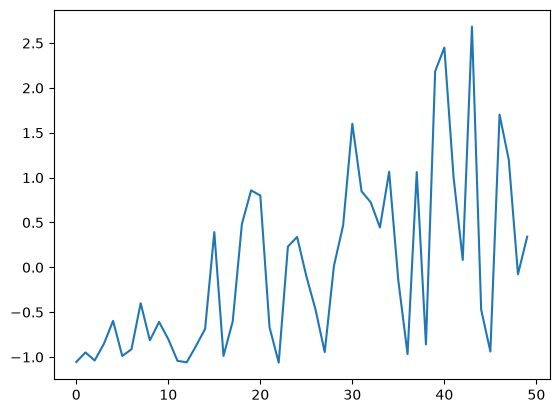

In [43]:
from sklearn import preprocessing
list_a = preprocessing.scale(list_a)
plt.plot(list_a)
plt.show()

In [ ]:
#로그변환만으로 완전한추세를 제거하기어려움 ->차분 

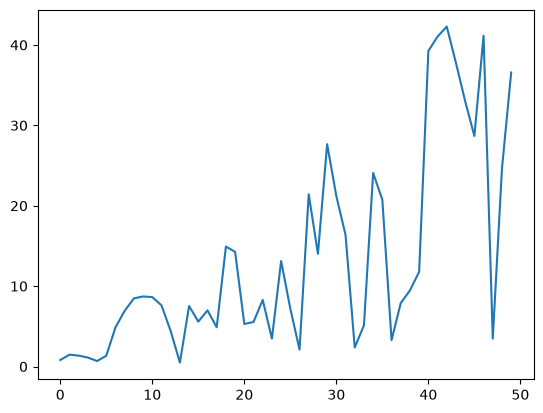

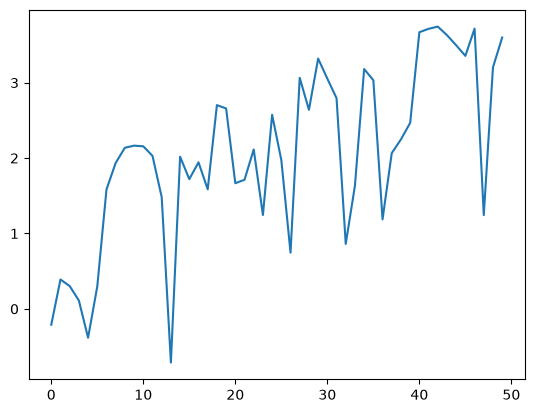

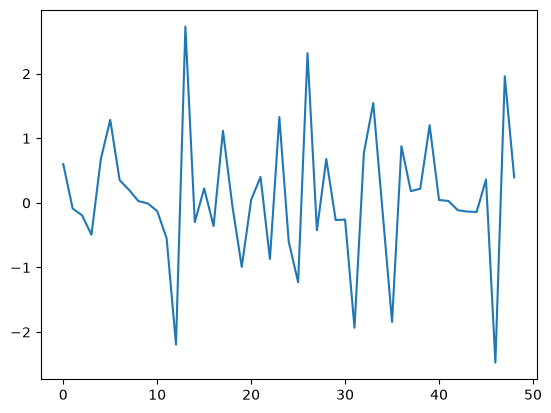

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt

#50개의 랜덤 시계열 생성
list_a=np.random.rand(50)

#idx만큼 증가하는 추세를 추가
list_a=[(idx+1)*val for idx,val in enumerate(list_a)]
plt.plot(list_a)
plt.show()

#로그변환
list_a = np.log(list_a)
plt.plot(list_a)
plt.show()

#차분
list_a=np.diff(list_a)
plt.plot(list_a)
plt.show()


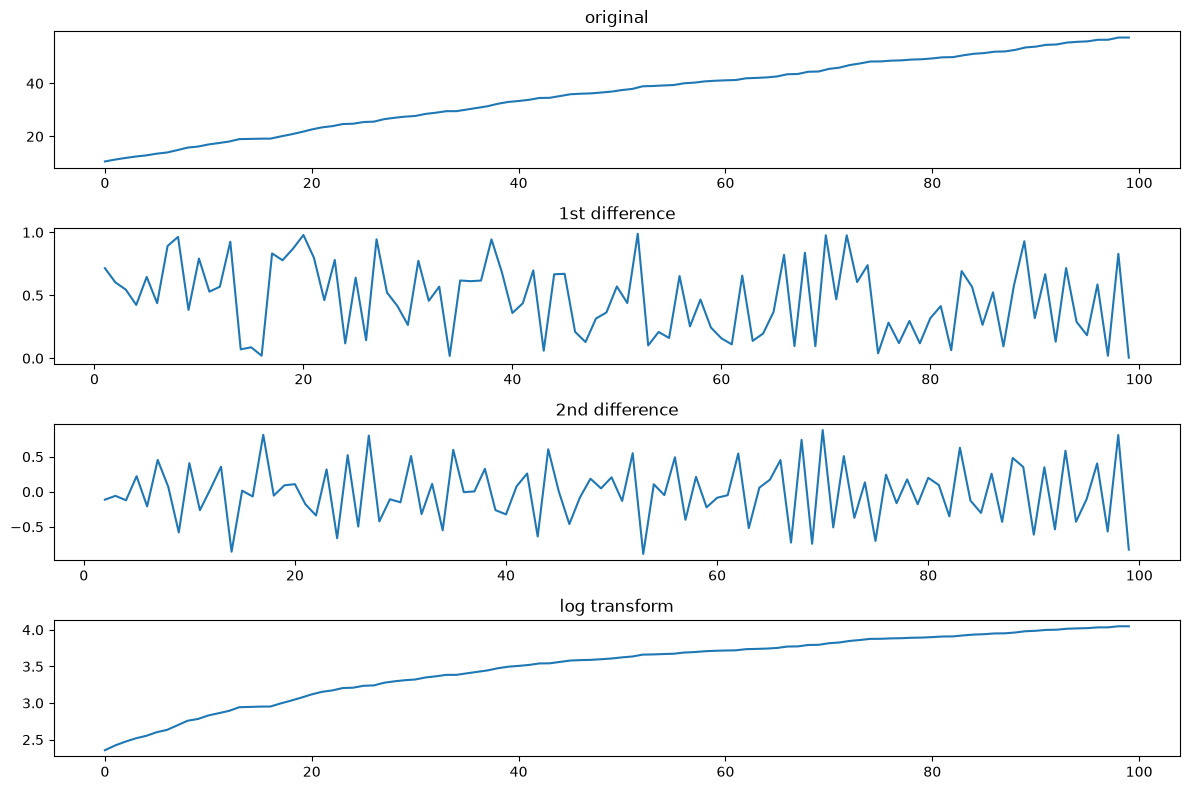

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
n = 100
data = np.cumsum(np.random.rand(n)) + 10
time_series = pd.Series(data)

# 1차 차분
diff_1 = time_series.diff()

# 2차 차분
diff_2 = diff_1.diff()

# 로그 변환
diff_3 = np.log(time_series)

plt.figure(figsize=(12, 8))

plt.subplot(4, 1, 1)
plt.plot(time_series)
plt.title("original")

plt.subplot(4, 1, 2)
plt.plot(diff_1)
plt.title("1st difference")

plt.subplot(4, 1, 3)
plt.plot(diff_2)
plt.title("2nd difference")

plt.subplot(4, 1, 4)
plt.plot(diff_3)
plt.title("log difference")

plt.tight_layout()
plt.show()

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
df = pd.read_csv("daily-total-female-births-CA.csv")
df.head()

,date,births
0,1959-01-01,35
1,1959-01-02,32
2,1959-01-03,30
3,1959-01-04,31
4,1959-01-05,44


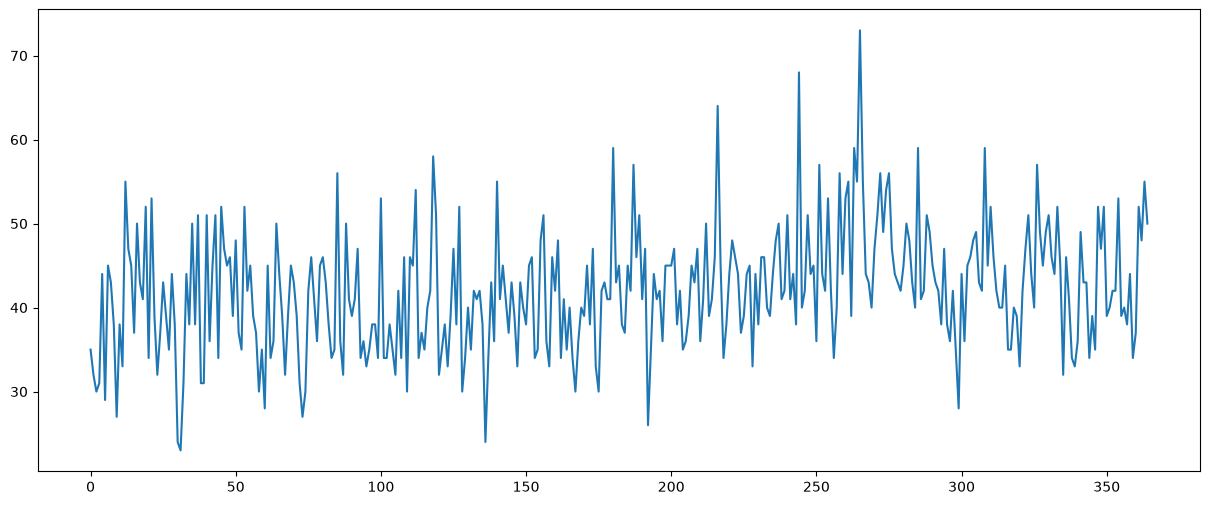

In [50]:
df.births.plot(figsize=(15,6))
plt.show()

In [51]:
timstamp=df.births

In [ ]:
##단순이동평균(simple Maoving Average,sma)

In [52]:
def SMA(array, window):
    array = np.array(array)
    assert array.ndim == 1, "1차원 array만 입력할 수 있습니다"
    n = len(array)

    result = np.empty(n)
    result[:] = np.nan

    ma = []
    # 0부터 n-window까지
    for i in range(0, n-window+1):
        m = np.mean(array[i:i+window])
        ma.append(m)

    result[window-1:] = ma

    return np.array(result)

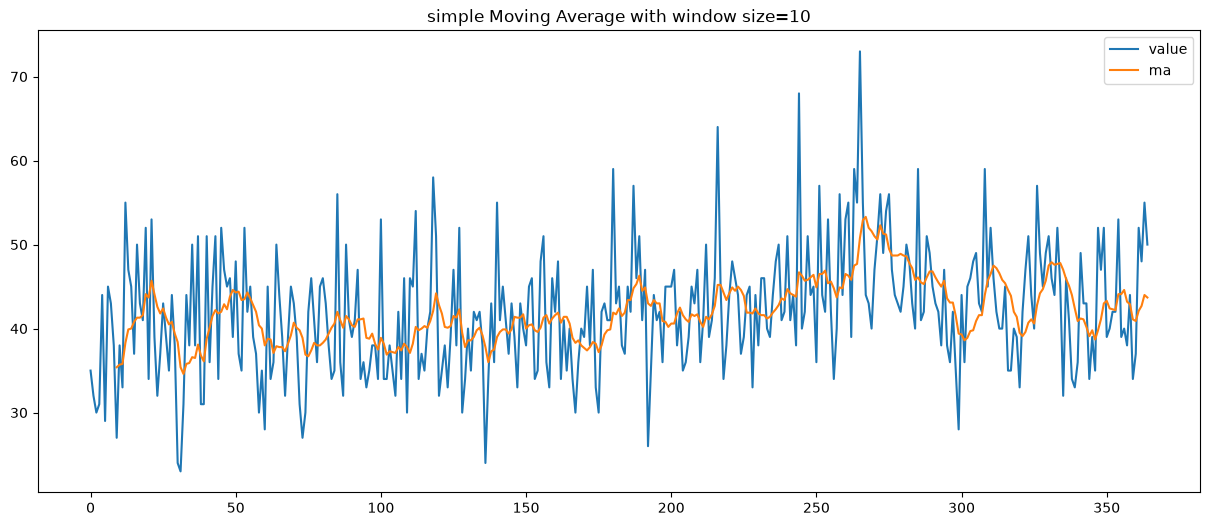

In [54]:
window = 10
sma = SMA(timstamp, window)

timstamp.plot(figsize=(15, 6))
plt.plot(sma)
plt.legend(["value", "ma"])
plt.title("simple Moving Average with window size={}".format(window))
plt.show()

##가중이동평균 
- list = [a0, a1, ..., an]
- window = m
- A = dot product([m, m-1, ..., 1], [ai, a(i-1), ..., a(i-m+1)])
- B = m + (m-1) + ... + 1
- ma_i = A / B
#가중치어떻게 줄지는 선택하기나름


In [ ]:
def WMA(array, window):
    array = np.array(array)
    assert array.ndim == 1, "1차원 array만 입력할 수 있습니다"
    n = len(array)

    result = np.empty(n)
    result[:] = np.nan

    weights = np.arange(1, window+1)   # [1, 2, ..., window] 최근 값일수록 큰 가중치

    ma = []
    # 0부터 n-window까지
    for i in range(0, n-window+1):
        m = np.average(array[i:i+window]weights=weights)
        ma.append(m)

    result[window-1:] = ma

    return np.array(result)

[nan nan 20. 30.]


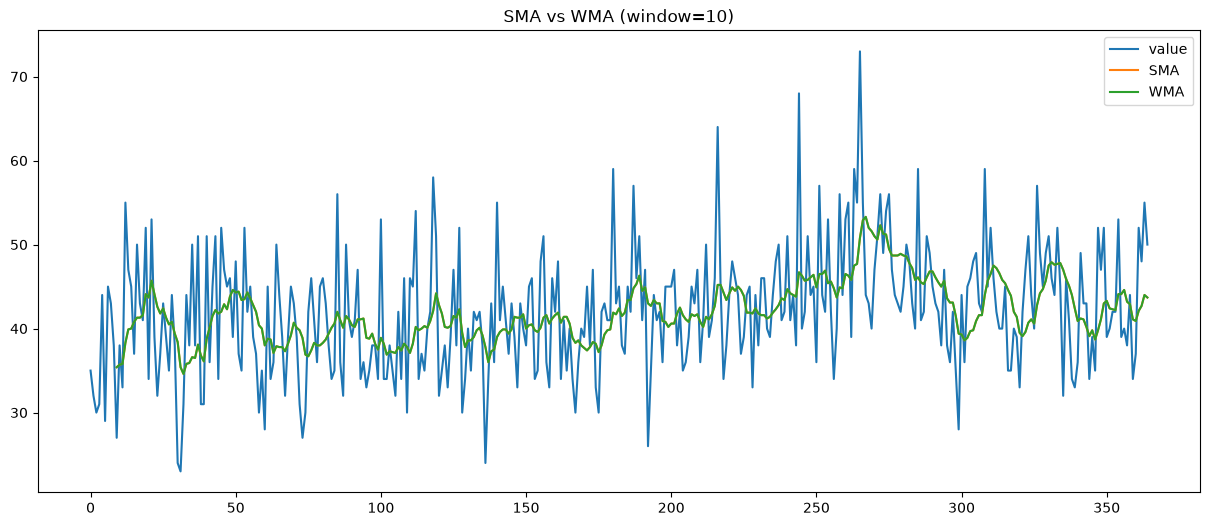

In [56]:
print(WMA([10, 20, 30, 40], 3))
# [ nan  nan 23.33 33.33]

window = 10
timstamp.plot(figsize=(15, 6))
plt.plot(SMA(timstamp, window))
plt.plot(WMA(timstamp, window))
plt.legend(["value", "SMA", "WMA"])
plt.title("SMA vs WMA (window={})".format(window))
plt.show()

In [ ]:
#누적이동평균 
#지수증가중이동평균
#지수평활법

In [2]:
%pip install statsmodels

  Using cached statsmodels-0.15.0-cp311-cp311-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
Using cached statsmodels-0.15.0-cp311-cp311-win_amd64.whl (11.4 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#지수평활법
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing



In [ ]:
# #데이터 생성(예시)
# data=[3,10,12,13,12,10,12,14,13,15,16,18,20,23,21]
# data_series=pd.Series(data)
# model=SimpleExpSmoothing(data_series)
# fit=model.fit(smoothing_level=0.2,optimized=False)
# fitted_values=fit.fittedvalues

# plt.plot(data_seriesm,label="orginal Data")
# plt.plot()
# plt.legend()
# plt.show()

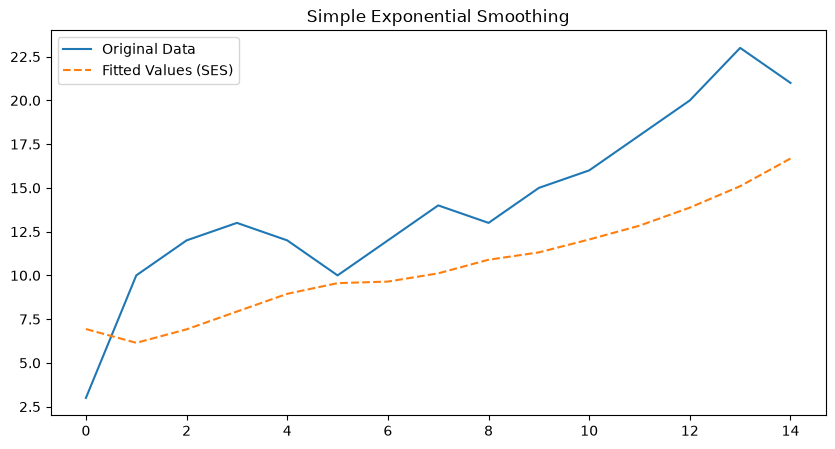

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# 데이터 생성(예시)
data = [3, 10, 12, 13, 12, 10, 12, 14, 13, 15, 16, 18, 20, 23, 21]
data_series = pd.Series(data)

model = SimpleExpSmoothing(data_series,initialization_method="estimated")
#initialization_method="estimated" = 초기 값을 모델 적합 과정에서 추정
fit = model.fit(smoothing_level=0.2, optimized=False)
fitted_values = fit.fittedvalues

plt.figure(figsize=(10, 5))
plt.plot(data_series, label="Original Data")
plt.plot(fitted_values, label="Fitted Values (SES)", linestyle="--")
plt.legend()
plt.title("Simple Exponential Smoothing")
plt.show()

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
df = pd.read_csv("./AAPL.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date")
df.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1980-12-12,0.128348,0.128906,0.128348,0.128348,0.100323,469033600
1980-12-15,0.122210,0.122210,0.121652,0.121652,0.095089,175884800
1980-12-16,0.113281,0.113281,0.112723,0.112723,0.088110,105728000
1980-12-17,0.115513,0.116071,0.115513,0.115513,0.090291,86441600
1980-12-18,0.118862,0.119420,0.118862,0.118862,0.092908,73449600


In [11]:
aapl = df.resample("ME").last().rename(columns={"Adj Close": "adj_close"}).adj_close
print(aapl)

Date
1980-12-31      0.119080
1981-01-31      0.098578
1981-02-28      0.092472
1981-03-31      0.085493
1981-04-30      0.099015
                 ...    
2021-11-30    165.089676
2021-12-31    177.344055
2022-01-31    174.557602
2022-02-28    165.119995
2022-03-31    174.070007
Freq: ME, Name: adj_close, Length: 496, dtype: float64


In [13]:
aapl_indices=aapl.index >= "2015-01-01"
aapl_2015=aapl[(aapl_indices)]
print(aapl_2015)


Date
2015-01-31     26.484514
2015-02-28     29.153534
2015-03-31     28.238945
2015-04-30     28.402336
2015-05-31     29.690079
                 ...    
2021-11-30    165.089676
2021-12-31    177.344055
2022-01-31    174.557602
2022-02-28    165.119995
2022-03-31    174.070007
Freq: ME, Name: adj_close, Length: 87, dtype: float64


<Axes: title={'center': 'Apple Stock Price'}, xlabel='Date'>

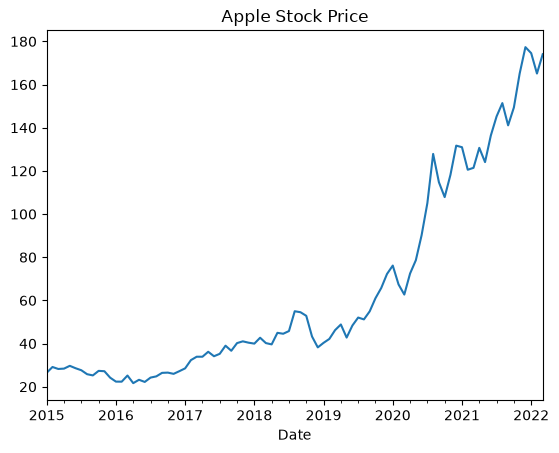

In [15]:
train_indices = aapl_2015.index < "2022-01-01"
aapl_train = aapl_2015[train_indices]
aapl_test = aapl_2015[~train_indices]

test_length = len(aapl_test)
aapl_2015.plot(title="Apple Stock Price")

In [17]:
ses_1 = SimpleExpSmoothing(aapl_train, initialization_method="estimated").fit(smoothing_level=0.2)
ses_forecast_1 = ses_1.forecast(test_length)

ses_2 = SimpleExpSmoothing(aapl_train, initialization_method="estimated").fit(smoothing_level=0.5)
ses_forecast_2 = ses_2.forecast(test_length)

ses_3 = SimpleExpSmoothing(aapl_train, initialization_method="estimated").fit()
alpha = ses_3.model.params['smoothing_level']
ses_forecast_3 = ses_3.forecast(test_length)

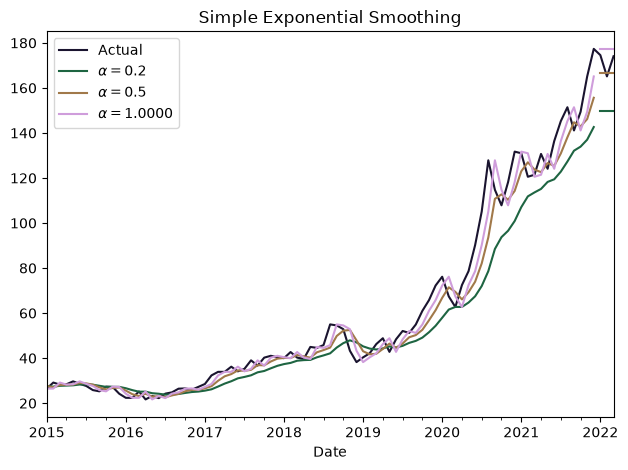

In [18]:
COLORS = [plt.cm.cubehelix(x) for x in [0.1, 0.3, 0.5, 0.7]]

aapl_2015.plot(color=COLORS[0], 
          title='Simple Exponential Smoothing',
          label='Actual',
          legend=True)

ses_forecast_1.plot(color=COLORS[1], legend=True, label=r'$\alpha=0.2$')
ses_1.fittedvalues.plot(color=COLORS[1])

ses_forecast_2.plot(color=COLORS[2], legend=True, label=r'$\alpha=0.5$')
ses_2.fittedvalues.plot(color=COLORS[2])

ses_forecast_3.plot(color=COLORS[3], legend=True, label=r'$\alpha={0:.4f}$'.format(alpha))
ses_3.fittedvalues.plot(color=COLORS[3])

plt.tight_layout()
plt.show()

In [ ]:
#보간법 예시 

In [19]:
#판다스의 interpolate()
import pandas as pd
import numpy as np

data={"A":[1,2,np.nan,4,5],"B":[5,np.nan,np.nan,8,9],"C":[9,10,11,12,13]}
df=pd.DataFrame(data)
print(df)

     A    B   C
0  1.0  5.0   9
1  2.0  NaN  10
2  NaN  NaN  11
3  4.0  8.0  12
4  5.0  9.0  13


In [20]:
df_interpolated2=df["A"].interpolate()
print(df_interpolated2)

0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
Name: A, dtype: float64


In [23]:
df_interpolated2=df.interpolate()
df_interpolated2

,A,B,C
0,1.0,5.0,9
1,2.0,6.0,10
2,3.0,7.0,11
3,4.0,8.0,12
4,5.0,9.0,13


In [24]:
df_interpolated = df.interpolate(method="polynomial",order=1) #1차함수
print(df_interpolated)

     A    B   C
0  1.0  5.0   9
1  2.0  6.0  10
2  3.0  7.0  11
3  4.0  8.0  12
4  5.0  9.0  13


In [25]:
df_interpolated = df.interpolate(method="polynomial",order=2) #2차함수
print(df_interpolated)

     A    B   C
0  1.0  5.0   9
1  2.0  6.0  10
2  3.0  7.0  11
3  4.0  8.0  12
4  5.0  9.0  13


In [26]:
df_interpolated2=df["A"].interpolate(method="spline",order=3)
print(df_interpolated2)

0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
Name: A, dtype: float64
